# Telco v2  - ?XGBoost tuning and feature importance (M1 - 3)

Run All from the repository root or `notebooks/`. Requires the v1 dependencies plus XGBoost >= 1.6 (constructor early stopping API). Only new v2 artifacts are written; v1 data, notebook and reports are read-only.

Protocol: reproduce v1 cleaning, 60/20/20 stratified split and preprocessing. Fit preprocessing on training only. Use the plan's holdout option: 80 seeded random candidates followed by a local grid, validation AP as primary objective and ROC-AUC as tie-breaker, validation `aucpr` early stopping (30 rounds). Manual ParameterSampler/ParameterGrid loops ensure the early-stopping eval_set receives the same trained transformation. This intentionally replaces the CV search wrappers in the plan; no CV scores are claimed. Reusing validation for search and thresholds may overfit validation; test data is reserved until all choices are locked. Do not refit on train+validation after selecting thresholds.

Permutation importance uses validation only (30 repeats, AP and ROC-AUC), on original columns through the fitted pipeline. Importance measures predictive association, not causal effects; correlated tenure/charges and service/contract fields can share or mask importance. SHAP is optional and omitted. M4 business reporting is outside this notebook.


Command-line execution and artifact checks: python scripts/run_v2.py from the repository root (requires nbformat, nbclient and ipykernel).

In [1]:
from pathlib import Path
import hashlib
import json
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import xgboost
from IPython.display import display
from sklearn.base import clone
from sklearn.model_selection import train_test_split, ParameterSampler, ParameterGrid
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_recall_curve,
    roc_curve, precision_score, recall_score, f1_score, confusion_matrix)
from xgboost import XGBClassifier

ROOT = Path.cwd() if (Path.cwd() / 'data/raw/Telco-Customer-Churn.csv').exists() else Path.cwd().parent
OUT, FIG = ROOT / 'reports', ROOT / 'reports/figures'
FIG.mkdir(parents=True, exist_ok=True)
SEED, N_RANDOM, N_REPEATS = 42, 80, 30
versions = {'python': platform.python_version(), 'numpy': np.__version__,
            'pandas': pd.__version__, 'sklearn': sklearn.__version__, 'xgboost': xgboost.__version__}
print(versions)
protected = [p for p in ROOT.rglob('*') if p.is_file() and '.git' not in p.parts
             and (p.relative_to(ROOT).parts[0] == 'data' or
                  p.relative_to(ROOT).as_posix() in ['notebooks/01_telco_churn.ipynb', 'reports/business_report.md', 'reports/model_comparison.csv']
                  or (p.parent == FIG and not p.name.startswith('v2_')))]
before = {p: hashlib.sha256(p.read_bytes()).hexdigest() for p in protected}


{'python': '3.13.14', 'numpy': '2.5.1', 'pandas': '3.0.3', 'sklearn': '1.9.1', 'xgboost': '3.4.1'}


## M1  - ?v1 cleaning, split and preprocessing parity


In [2]:
raw = pd.read_csv(ROOT / 'data/raw/Telco-Customer-Churn.csv')
df = raw.copy()
for col in df.select_dtypes(include='object'):
    df[col] = df[col].str.strip().replace('', np.nan)
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
assert df.customerID.notna().all() and df.customerID.is_unique
assert df.Churn.isin(['Yes', 'No']).all()
# Compare with the persisted v1 cleaning without overwriting it.
pd.testing.assert_frame_equal(df, pd.read_csv(ROOT / 'data/processed/telco_cleaned.csv'))
X = df.drop(columns=['customerID', 'Churn'])
y = df.Churn.eq('Yes').astype(int)
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=.4, stratify=y, random_state=42)
X_valid, X_test, y_valid, y_test = train_test_split(X_temp, y_temp, test_size=.5, stratify=y_temp, random_state=42)
assert (len(X_train), len(X_valid), len(X_test)) == (4225, 1409, 1409)
assert not (set(X_train.index) & set(X_valid.index) or set(X_train.index) & set(X_test.index)
            or set(X_valid.index) & set(X_test.index))
num = X.select_dtypes(include='number').columns.tolist()
cat = X.select_dtypes(exclude='number').columns.tolist()
preprocess = ColumnTransformer([
    ('num', Pipeline([('impute', SimpleImputer(strategy='median')), ('scale', StandardScaler())]), num),
    ('cat', Pipeline([('impute', SimpleImputer(strategy='most_frequent')), ('onehot', OneHotEncoder(handle_unknown='ignore'))]), cat)
])
trained_preprocess = clone(preprocess).fit(X_train)
train_encoded = trained_preprocess.transform(X_train)
valid_encoded = trained_preprocess.transform(X_valid)
print('Train / validation / test:', len(X_train), len(X_valid), len(X_test))
print('Encoded columns:', train_encoded.shape[1])


Train / validation / test:

 4225 1409 1409
Encoded columns: 45


C:\Users\13557\AppData\Local\Temp\ipykernel_40040\782054061.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include='object'):


## M2  - ?seeded random search, local refinement and early stopping


Random candidates: 10/80; best validation AP: 0.6820


Random candidates: 20/80; best validation AP: 0.6864


Random candidates: 30/80; best validation AP: 0.6864


Random candidates: 40/80; best validation AP: 0.6864


Random candidates: 50/80; best validation AP: 0.6864


Random candidates: 60/80; best validation AP: 0.6864


Random candidates: 70/80; best validation AP: 0.6864


Random candidates: 80/80; best validation AP: 0.6866


,stage,subsample,scale_pos_weight,reg_lambda,reg_alpha,n_estimators,min_child_weight,max_depth,learning_rate,gamma,colsample_bytree,validation_pr_auc,validation_roc_auc,best_iteration,rounds_run
85,local_grid,0.6,2.77,0.5,5.0,200,3,3,0.20,2.0,0.6,0.687311,0.861061,41,72
74,random,0.6,2.77,0.5,5.0,200,3,2,0.20,2.0,0.6,0.686621,0.859708,49,80
84,local_grid,0.6,2.77,1.0,5.0,200,3,2,0.20,2.0,0.6,0.686566,0.859706,49,80
13,random,0.7,2.77,2.0,1.0,200,5,5,0.05,0.5,0.6,0.686450,0.860367,80,111
86,local_grid,0.6,2.77,1.0,5.0,200,3,3,0.20,2.0,0.6,0.685231,0.859538,58,89
81,local_grid,0.6,2.77,1.0,5.0,200,3,2,0.10,2.0,0.6,0.685067,0.860013,100,131
80,local_grid,0.6,2.77,0.5,5.0,200,3,2,0.10,2.0,0.6,0.684952,0.860158,98,129
79,random,0.8,1.50,1.0,0.1,200,10,3,0.05,2.0,0.5,0.684094,0.861242,123,154
47,random,0.8,1.50,0.5,1.0,300,1,3,0.05,2.0,0.7,0.683787,0.860092,76,107
68,random,0.8,2.77,10.0,0.0,300,1,4,0.10,0.1,0.8,0.683786,0.858781,46,77


Locked parameters: {'colsample_bytree': 0.6, 'gamma': 2.0, 'learning_rate': 0.2, 'max_depth': 3, 'min_child_weight': 3, 'n_estimators': 200, 'reg_alpha': 5.0, 'reg_lambda': 0.5, 'scale_pos_weight': 2.77, 'subsample': 0.6} best iteration (zero-based): 41


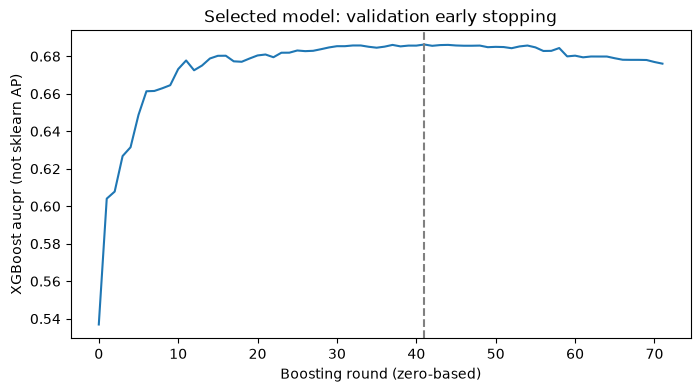

In [3]:
space = {
    'max_depth': [2, 3, 4, 5, 6], 'min_child_weight': [1, 3, 5, 10, 15],
    'learning_rate': [.01, .03, .05, .1, .2], 'n_estimators': [100, 200, 300, 500, 800],
    'subsample': [.6, .7, .8, .9, 1.], 'colsample_bytree': [.5, .6, .7, .8, 1.],
    'gamma': [0, .1, .5, 1., 2.], 'reg_alpha': [0, .01, .1, 1., 5.],
    'reg_lambda': [.5, 1., 2., 5., 10.], 'scale_pos_weight': [1., 1.5, 2.77]
}
search_rows, seen = [], set()
best_model, best_params, best_score = None, None, (-np.inf, -np.inf)
def evaluate_candidate(params, stage):
    global best_model, best_params, best_score
    key = json.dumps(params, sort_keys=True)
    if key in seen:
        return
    seen.add(key)
    model = XGBClassifier(**params, random_state=SEED, n_jobs=4,
                          eval_metric='aucpr', early_stopping_rounds=30)
    model.fit(train_encoded, y_train, eval_set=[(valid_encoded, y_valid)], verbose=False)
    prob = model.predict_proba(valid_encoded)[:, 1]
    score = (average_precision_score(y_valid, prob), roc_auc_score(y_valid, prob))
    search_rows.append(dict(stage=stage, **params, validation_pr_auc=score[0],
                            validation_roc_auc=score[1], best_iteration=model.best_iteration,
                            rounds_run=len(model.evals_result()['validation_0']['aucpr'])))
    if score > best_score:
        best_model, best_params, best_score = model, params.copy(), score

for i, params in enumerate(ParameterSampler(space, n_iter=N_RANDOM, random_state=SEED), 1):
    evaluate_candidate(params, 'random')
    if i % 10 == 0:
        print(f'Random candidates: {i}/{N_RANDOM}; best validation AP: {best_score[0]:.4f}')
# Adjacent depth, learning rate and L2 values around the winning random candidate.
anchor = best_params.copy()
local = {k: [v] for k, v in anchor.items()}
for k in ['max_depth', 'learning_rate', 'reg_lambda']:
    values = space[k]
    pos = values.index(anchor[k])
    local[k] = values[max(0, pos - 1):pos + 2]
for params in ParameterGrid(local):
    evaluate_candidate(params, 'local_grid')
search = pd.DataFrame(search_rows).sort_values(['validation_pr_auc', 'validation_roc_auc'], ascending=False)
search.to_csv(OUT / 'search_results_v2.csv', index=False)
display(search.head(10))
print('Locked parameters:', best_params, 'best iteration (zero-based):', best_model.best_iteration)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(best_model.evals_result()['validation_0']['aucpr'])
ax.axvline(best_model.best_iteration, color='gray', linestyle='--')
ax.set(title='Selected model: validation early stopping', xlabel='Boosting round (zero-based)', ylabel='XGBoost aucpr (not sklearn AP)')
plt.show()


,validation_threshold,roc_auc,pr_auc,precision,recall,f1,tn,fp,fn,tp,contacted
model,,,,,,,,,,,
XGBoost (v2 Tuned),0.5790,0.8373,0.6440,0.5453,0.7406,0.6281,804,231,97,277,508
Logistic Regression,0.4947,0.8324,0.6221,0.6142,0.5321,0.5702,910,125,175,199,324
Random Forest,0.3209,0.8063,0.5914,0.5210,0.6979,0.5966,795,240,113,261,501
XGBoost (v1 Default),0.1704,0.7856,0.5583,0.4837,0.6765,0.5641,765,270,121,253,523


Baselines rerun under the recorded versions; historical v1 CSV is preserved.


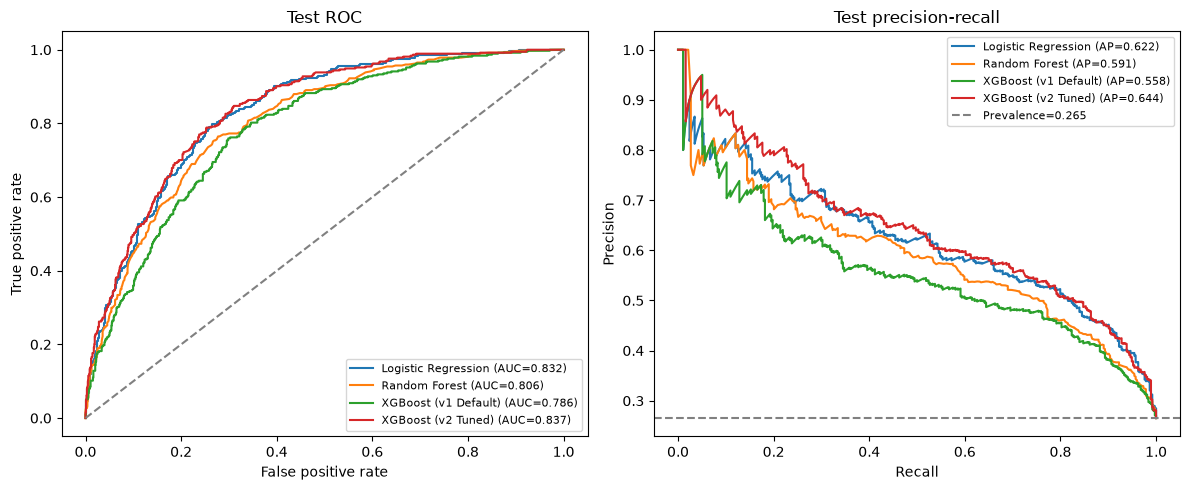

In [4]:
fitted = {}
for name, model in {
    'Logistic Regression': LogisticRegression(max_iter=2000, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1),
    'XGBoost (v1 Default)': XGBClassifier(n_estimators=300, random_state=42, n_jobs=-1, eval_metric='logloss')
}.items():
    fitted[name] = Pipeline([('preprocess', clone(preprocess)), ('model', model)]).fit(X_train, y_train)
fitted['XGBoost (v2 Tuned)'] = Pipeline([('preprocess', trained_preprocess), ('model', best_model)])
thresholds = {}
for name, pipe in fitted.items():
    p, r, ts = precision_recall_curve(y_valid, pipe.predict_proba(X_valid)[:, 1])
    scores = 2 * p[:-1] * r[:-1] / np.maximum(p[:-1] + r[:-1], 1e-12)
    thresholds[name] = float(ts[np.argmax(scores)])
# All models and thresholds are now locked; test labels were not used in selection.
results, probabilities = [], {}
for name, pipe in fitted.items():
    prob = pipe.predict_proba(X_test)[:, 1]
    pred = (prob >= thresholds[name]).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
    results.append(dict(model=name, validation_threshold=thresholds[name],
        roc_auc=roc_auc_score(y_test, prob), pr_auc=average_precision_score(y_test, prob),
        precision=precision_score(y_test, pred, zero_division=0), recall=recall_score(y_test, pred, zero_division=0),
        f1=f1_score(y_test, pred, zero_division=0), tn=tn, fp=fp, fn=fn, tp=tp, contacted=int(pred.sum())))
    probabilities[name] = prob
metrics = pd.DataFrame(results).set_index('model').sort_values('pr_auc', ascending=False)
assert (metrics[['tn', 'fp', 'fn', 'tp']].sum(axis=1) == len(y_test)).all()
assert (metrics.contacted == metrics.tp + metrics.fp).all()
metrics.to_csv(OUT / 'model_comparison_v2.csv')
display(metrics.round(4))
print('Baselines rerun under the recorded versions; historical v1 CSV is preserved.')
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for name, prob in probabilities.items():
    fpr, tpr, _ = roc_curve(y_test, prob)
    p, r, _ = precision_recall_curve(y_test, prob)
    axes[0].plot(fpr, tpr, label=f'{name} (AUC={metrics.loc[name, "roc_auc"]:.3f})')
    axes[1].plot(r, p, label=f'{name} (AP={metrics.loc[name, "pr_auc"]:.3f})')
axes[0].plot([0, 1], [0, 1], '--', color='gray')
axes[0].set(title='Test ROC', xlabel='False positive rate', ylabel='True positive rate')
axes[1].axhline(y_test.mean(), color='gray', linestyle='--', label=f'Prevalence={y_test.mean():.3f}')
axes[1].set(title='Test precision-recall', xlabel='Recall', ylabel='Precision')
for ax in axes:
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG / 'v2_04_model_curves.png', dpi=160)
plt.show()


## M3  - ?encoded and original-column importance, cross-model comparison


,feature,original_feature,gain,weight,cover,lr_coefficient,lr_abs_coefficient
36,cat__Contract_Month-to-month,Contract,276.442688,7.0,650.358398,0.592012,0.592012
27,cat__TechSupport_No,TechSupport,105.143745,6.0,527.553467,0.154534,0.154534
37,cat__Contract_One year,Contract,40.075409,1.0,682.283752,-0.115246,0.115246
18,cat__OnlineSecurity_No,OnlineSecurity,36.408573,9.0,312.648254,0.159900,0.159900
38,cat__Contract_Two year,Contract,34.153648,9.0,527.259521,-0.767353,0.767353
16,cat__InternetService_Fiber optic,InternetService,21.936485,9.0,405.622681,0.475731,0.475731
43,cat__PaymentMethod_Electronic check,PaymentMethod,20.956869,8.0,417.689880,0.215070,0.215070
35,cat__StreamingMovies_Yes,StreamingMovies,15.830847,4.0,288.495422,0.140632,0.140632
15,cat__InternetService_DSL,InternetService,14.842774,4.0,276.741882,-0.525734,0.525734
1,num__tenure,tenure,13.834659,42.0,355.645081,-1.264101,1.264101


,encoded_gain_sum,weight,encoded_cover_sum,lr_abs_coefficient,gain_share,xgb_ap_mean,xgb_ap_std,xgb_ap_q025,xgb_ap_q975,xgb_roc_auc_mean,...,xgb_roc_auc_q025,xgb_roc_auc_q975,rf_ap_mean,rf_ap_std,rf_ap_q025,rf_ap_q975,rf_roc_auc_mean,rf_roc_auc_std,rf_roc_auc_q025,rf_roc_auc_q975
feature,,,,,,,,,,,,,,,,,,,,,
Contract,350.671745,17.0,1859.901672,1.474610,0.486840,0.104732,0.013737,0.079908,0.128540,0.080453,...,0.067075,0.094006,0.063063,0.011216,0.042790,0.083787,0.049424,0.005110,0.041423,0.060434
tenure,13.834659,42.0,355.645081,1.264101,0.019207,0.099969,0.015102,0.069755,0.125194,0.042020,...,0.033781,0.048989,0.042759,0.011523,0.020547,0.060370,0.016384,0.003117,0.011287,0.022776
InternetService,36.779260,13.0,682.364563,1.242049,0.051061,0.040927,0.012168,0.020644,0.060734,0.015627,...,0.010940,0.022148,0.034773,0.012928,0.008266,0.056893,0.011109,0.004097,0.005471,0.019146
PaperlessBilling,15.963953,9.0,814.033539,0.382504,0.022163,0.023004,0.007406,0.010471,0.036397,0.006943,...,0.003322,0.009997,0.014465,0.008791,0.000070,0.032500,0.007775,0.003635,0.002597,0.014395
TotalCharges,13.294678,18.0,294.677124,0.584721,0.018457,0.021985,0.009413,0.004843,0.037529,0.007568,...,0.004550,0.010087,0.011414,0.008092,-0.003746,0.025232,0.003120,0.002490,-0.001471,0.006992
TechSupport,108.178668,7.0,1050.579590,0.599655,0.150185,0.013777,0.007963,-0.000178,0.028328,0.006498,...,0.002592,0.010115,0.003179,0.010981,-0.012542,0.022419,0.004416,0.002749,0.000159,0.009792
OnlineSecurity,39.018877,10.0,899.598267,0.610387,0.054170,0.013032,0.007948,-0.002316,0.026166,0.006012,...,0.002561,0.008850,0.009664,0.011386,-0.012048,0.025384,0.003879,0.002855,-0.003016,0.008100
PaymentMethod,32.239608,10.0,1022.631248,0.720727,0.044758,0.012716,0.006224,0.003465,0.022394,0.007410,...,0.004637,0.010882,0.002872,0.011008,-0.012773,0.021911,0.003760,0.003534,-0.002023,0.010093
MonthlyCharges,9.366048,39.0,316.813385,0.335729,0.013003,0.008997,0.004508,0.000464,0.016827,0.003876,...,0.000742,0.006939,-0.012768,0.007667,-0.026948,0.001115,-0.006603,0.002439,-0.011181,-0.002565


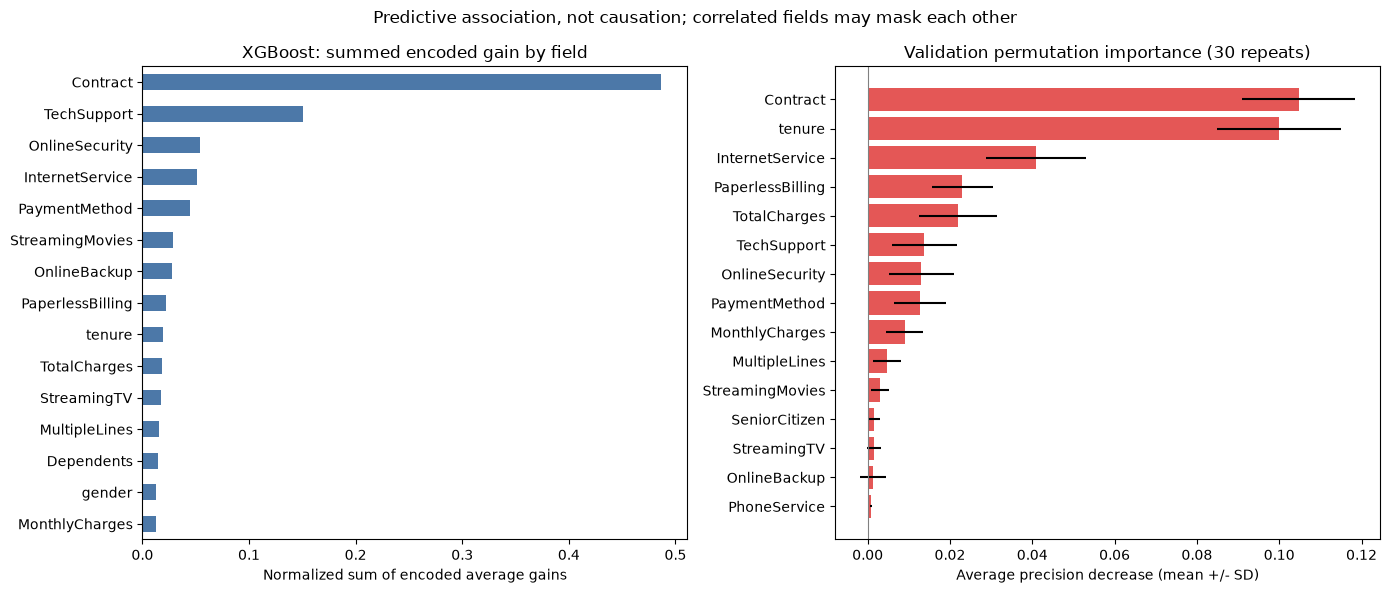

,gain_share,lr_abs_coefficient,rf_ap_mean,xgb_ap_mean
feature,,,,
Contract,1.0,1.0,1.0,1.0
tenure,9.0,2.0,2.0,2.0
InternetService,4.0,3.0,3.0,3.0
PaperlessBilling,8.0,11.0,4.0,4.0
TotalCharges,10.0,7.0,5.0,5.0
TechSupport,2.0,6.0,7.0,6.0
OnlineSecurity,3.0,5.0,6.0,7.0
PaymentMethod,5.0,4.0,8.0,8.0
MonthlyCharges,15.0,13.0,18.0,9.0


Permutation quantiles describe shuffle variability, not population confidence intervals.
LR numerical coefficients use standardized inputs; dummy coefficients are category contrasts.


In [5]:
names = trained_preprocess.get_feature_names_out()
# Map by transformer output order and fitted categories; never split names on underscores.
onehot = trained_preprocess.named_transformers_['cat'].named_steps['onehot']
original = num + [col for col, categories in zip(cat, onehot.categories_) for _ in categories]
assert len(names) == len(original) == train_encoded.shape[1]
encoded = pd.DataFrame({'feature': names, 'original_feature': original})
# Match the tree range used by predict_proba after early stopping.
booster = best_model.get_booster()[:best_model.best_iteration + 1]
for kind in ['gain', 'weight', 'cover']:
    values = booster.get_score(importance_type=kind)
    encoded[kind] = [values.get(f'f{i}', 0.) for i in range(len(names))]
encoded['lr_coefficient'] = fitted['Logistic Regression'].named_steps['model'].coef_[0]
encoded['lr_abs_coefficient'] = encoded.lr_coefficient.abs()
encoded.to_csv(OUT / 'feature_importance_encoded_v2.csv', index=False)
display(encoded.nlargest(15, 'gain'))
importance = encoded.groupby('original_feature')[['gain', 'weight', 'cover', 'lr_abs_coefficient']].sum()
importance.index.name = 'feature'
# Aggregated gain/cover are sums of encoded mean gain/cover, not pooled split-weighted averages.
importance = importance.rename(columns={'gain': 'encoded_gain_sum', 'cover': 'encoded_cover_sum'})
importance['gain_share'] = importance.encoded_gain_sum / importance.encoded_gain_sum.sum()
for name, prefix in [('XGBoost (v2 Tuned)', 'xgb'), ('Random Forest', 'rf')]:
    perm = permutation_importance(fitted[name], X_valid, y_valid,
        scoring=['average_precision', 'roc_auc'], n_repeats=N_REPEATS, random_state=SEED, n_jobs=1)
    for scorer, short in [('average_precision', 'ap'), ('roc_auc', 'roc_auc')]:
        result = perm[scorer]
        table = pd.DataFrame({f'{prefix}_{short}_mean': result.importances_mean,
                              f'{prefix}_{short}_std': result.importances_std,
                              f'{prefix}_{short}_q025': np.quantile(result.importances, .025, axis=1),
                              f'{prefix}_{short}_q975': np.quantile(result.importances, .975, axis=1)}, index=X.columns)
        importance = importance.join(table)
importance = importance.sort_values('xgb_ap_mean', ascending=False)
assert len(importance) == X.shape[1] and importance.notna().all().all()
importance.to_csv(OUT / 'feature_importance_v2.csv')
display(importance)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
gain = importance.nlargest(15, 'gain_share').sort_values('gain_share')
gain.gain_share.plot.barh(ax=axes[0], color='#4c78a8')
axes[0].set(title='XGBoost: summed encoded gain by field', xlabel='Normalized sum of encoded average gains', ylabel='')
top = importance.head(15).sort_values('xgb_ap_mean')
axes[1].barh(top.index, top.xgb_ap_mean, xerr=top.xgb_ap_std, color='#e45756')
axes[1].axvline(0, color='gray', linewidth=.8)
axes[1].set(title='Validation permutation importance (30 repeats)', xlabel='Average precision decrease (mean +/- SD)')
fig.suptitle('Predictive association, not causation; correlated fields may mask each other')
fig.tight_layout()
fig.savefig(FIG / 'v2_05_feature_importance.png', dpi=160)
plt.show()
# Side-by-side evidence for cross-model consistency; magnitudes have different units.
display(importance[['gain_share', 'lr_abs_coefficient', 'rf_ap_mean', 'xgb_ap_mean']].rank(ascending=False).sort_values('xgb_ap_mean'))
print('Permutation quantiles describe shuffle variability, not population confidence intervals.')
print('LR numerical coefficients use standardized inputs; dummy coefficients are category contrasts.')


In [6]:
metadata = {'versions': versions, 'seed': SEED, 'random_candidates': N_RANDOM,
    'search_candidates': len(search), 'best_params': best_params, 'best_iteration': best_model.best_iteration,
    'early_stopping_rounds': 30, 'permutation_repeats': N_REPEATS,
    'selection': 'validation AP, then ROC-AUC', 'validation_thresholds': thresholds,
    'raw_sha256': hashlib.sha256((ROOT / 'data/raw/Telco-Customer-Churn.csv').read_bytes()).hexdigest(),
    'split_customer_ids': {name: df.loc[part.index, 'customerID'].tolist()
                           for name, part in [('train', X_train), ('validation', X_valid), ('test', X_test)]}}
(OUT / 'run_metadata_v2.json').write_text(json.dumps(metadata, indent=2), encoding='utf-8')
assert all(hashlib.sha256(p.read_bytes()).hexdigest() == digest for p, digest in before.items()), 'v1 file changed'
for path in ['reports/model_comparison_v2.csv', 'reports/feature_importance_v2.csv',
             'reports/figures/v2_04_model_curves.png', 'reports/figures/v2_05_feature_importance.png']:
    assert (ROOT / path).stat().st_size > 0, path
print('M1 - 3 complete. Required artifacts exist; protected v1 files are unchanged.')


M1 - 3 complete. Required artifacts exist; protected v1 files are unchanged.
